# A. Normalisation de données

In [54]:
import numpy as np
import pandas as pd
import sklearn as sk
import sklearn.preprocessing as prep
import sklearn.datasets as datasets
import matplotlib.pyplot as plt


In [55]:
X = np.array([[1,-1,2],[2,0,0],[0,1,-1]])
print(X)
print(np.var(X), np.mean(X))

[[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]
1.1358024691358024 0.4444444444444444


In [56]:
Xnormaliser = np.array(prep.scale(X))
print(Xnormaliser)

[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]


3) Nos données sont centrées et réduites.

In [57]:
print(np.var(Xnormaliser), np.mean(Xnormaliser))

1.0 4.9343245538895844e-17


# B. Normalisation MinMax

In [58]:
X2 = np.array([[1,-1, 2],[2, 0, 0],[0, 1,-1]])
print(X2)

[[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]


In [59]:
print(np.mean(X2[0]), np.mean(X2[1]), np.mean(X2[2]))

print(np.var(X2[0]), np.var(X2[1]), np.var(X2[2]))


0.6666666666666666 0.6666666666666666 0.0
1.5555555555555554 0.888888888888889 0.6666666666666666


3) on normalise dans l'intervalle [0,1]

In [60]:
scaler = prep.MinMaxScaler((0,1))
scaler.fit(X2)
print(scaler.transform(X2))

[[0.5        0.         1.        ]
 [1.         0.5        0.33333333]
 [0.         1.         0.        ]]


In [61]:
X2_01 = np.array(scaler.transform(X2))

print(np.mean(X2[0]), np.mean(X2[1]), np.mean(X2[2]))

print(np.var(X2[0]), np.var(X2[1]), np.var(X2[2]))


0.6666666666666666 0.6666666666666666 0.0
1.5555555555555554 0.888888888888889 0.6666666666666666


3) On constate que les données sont bien mises sur une echelle de 0,1, les moyennes et variances sont préservées

# C. Visualisation de données

In [62]:
iris1 = datasets.load_iris()

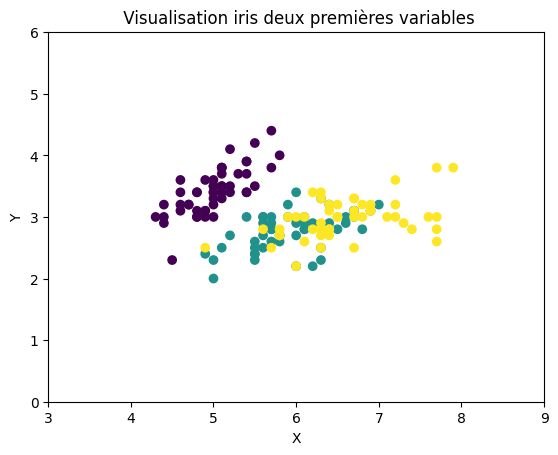

In [63]:
plt.scatter(iris1.data[:,0], iris1.data[:,1],c =iris1.target)
plt.title(" Visualisation iris deux premières variables")
plt.xlim([3, 9])
plt.ylim([0, 6])
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

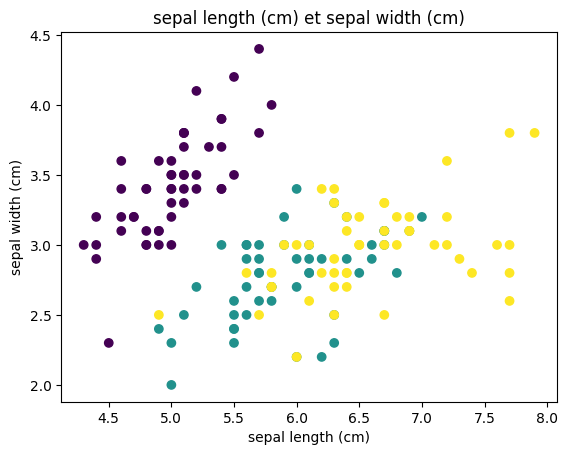

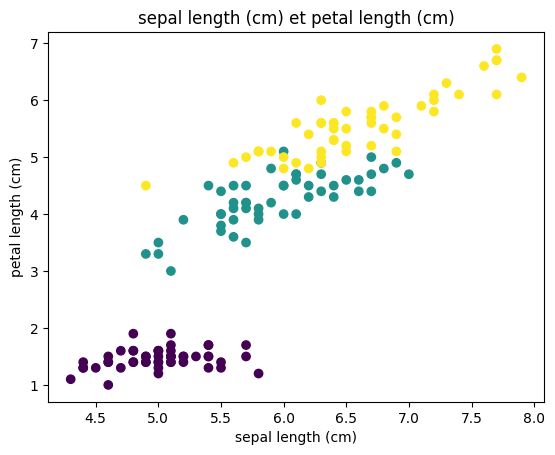

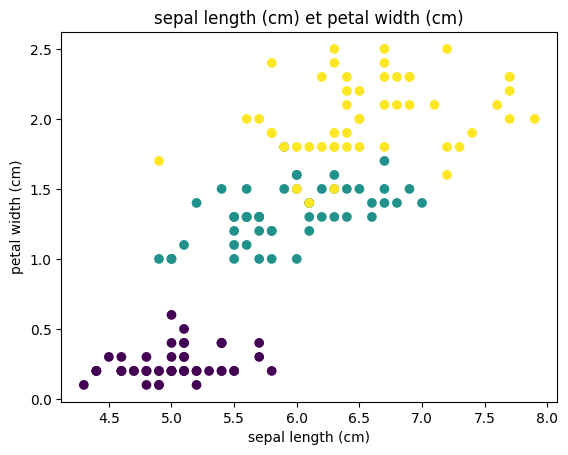

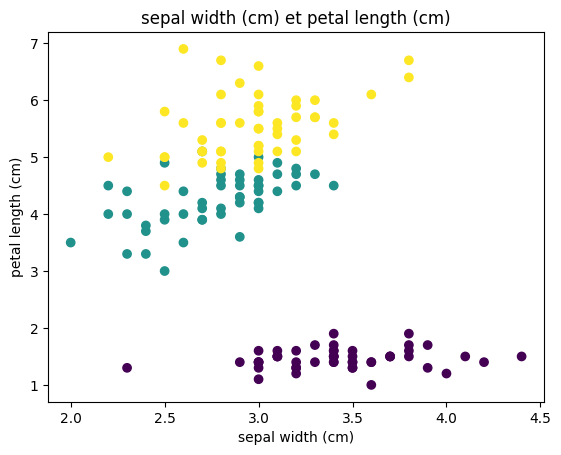

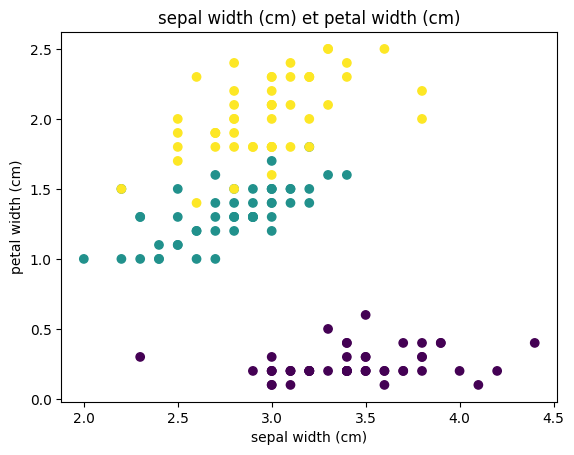

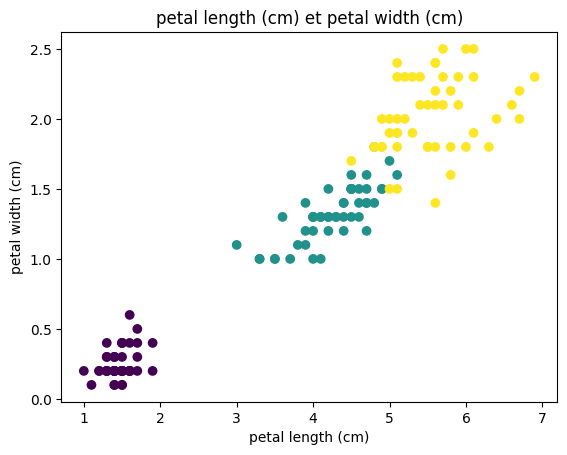

In [85]:
for i in range(4) :
    for j in range(i + 1, 4): 
        if i != j :
            plt.scatter(iris1.data[:,i], iris1.data[:,j],c = iris1.target)
            plt.title(f"{iris1.feature_names[i]} et {iris1.feature_names[j]}")
            plt.xlabel(f"{iris1.feature_names[i]}")
            plt.ylabel(f"{iris1.feature_names[j]}")
            plt.show()

2) La meilleure visualisation est celle où les groupes sont le plus distinct et les individus aussi. En dehors du premier graphique les autres sont plutôt bien représentés avec une bonne séparation entre les groupes, je choisirai probablement le 5ème qui semble bien avoir ses trois groupes bien définis avec une bonne séparation des individus mais l'échelle de chaque graphique pourrait induire en erreur.

# D. Réduction de dimensions et visualisation de données

In [66]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

In [67]:
help(PCA)

Help on class PCA in module sklearn.decomposition._pca:

class PCA(sklearn.decomposition._base._BasePCA)
 |  PCA(n_components=None, *, copy=True, whiten=False, svd_solver='auto', tol=0.0, iterated_power='auto', n_oversamples=10, power_iteration_normalizer='auto', random_state=None)
 |  
 |  Principal component analysis (PCA).
 |  
 |  Linear dimensionality reduction using Singular Value Decomposition of the
 |  data to project it to a lower dimensional space. The input data is centered
 |  but not scaled for each feature before applying the SVD.
 |  
 |  It uses the LAPACK implementation of the full SVD or a randomized truncated
 |  SVD by the method of Halko et al. 2009, depending on the shape of the input
 |  data and the number of components to extract.
 |  
 |  With sparse inputs, the ARPACK implementation of the truncated SVD can be
 |  used (i.e. through :func:`scipy.sparse.linalg.svds`). Alternatively, one
 |  may consider :class:`TruncatedSVD` where the data are not centered.
 

In [ ]:
pca = PCA(n_components=2)
pca.fit(iris1.data)
print(pca.explained_variance_ratio_)
print(pca.singular_values_)


[0.92461872 0.05306648]
[25.09996044  6.01314738]


In [74]:
IrisPCA = pca.fit(iris1.data).transform(iris1.data)
print(IrisPCA)

[[-2.68412563  0.31939725]
 [-2.71414169 -0.17700123]
 [-2.88899057 -0.14494943]
 [-2.74534286 -0.31829898]
 [-2.72871654  0.32675451]
 [-2.28085963  0.74133045]
 [-2.82053775 -0.08946138]
 [-2.62614497  0.16338496]
 [-2.88638273 -0.57831175]
 [-2.6727558  -0.11377425]
 [-2.50694709  0.6450689 ]
 [-2.61275523  0.01472994]
 [-2.78610927 -0.235112  ]
 [-3.22380374 -0.51139459]
 [-2.64475039  1.17876464]
 [-2.38603903  1.33806233]
 [-2.62352788  0.81067951]
 [-2.64829671  0.31184914]
 [-2.19982032  0.87283904]
 [-2.5879864   0.51356031]
 [-2.31025622  0.39134594]
 [-2.54370523  0.43299606]
 [-3.21593942  0.13346807]
 [-2.30273318  0.09870885]
 [-2.35575405 -0.03728186]
 [-2.50666891 -0.14601688]
 [-2.46882007  0.13095149]
 [-2.56231991  0.36771886]
 [-2.63953472  0.31203998]
 [-2.63198939 -0.19696122]
 [-2.58739848 -0.20431849]
 [-2.4099325   0.41092426]
 [-2.64886233  0.81336382]
 [-2.59873675  1.09314576]
 [-2.63692688 -0.12132235]
 [-2.86624165  0.06936447]
 [-2.62523805  0.59937002]
 

In [75]:
help(LDA)

Help on class LinearDiscriminantAnalysis in module sklearn.discriminant_analysis:

class LinearDiscriminantAnalysis(sklearn.base.ClassNamePrefixFeaturesOutMixin, sklearn.linear_model._base.LinearClassifierMixin, sklearn.base.TransformerMixin, sklearn.base.BaseEstimator)
 |  LinearDiscriminantAnalysis(solver='svd', shrinkage=None, priors=None, n_components=None, store_covariance=False, tol=0.0001, covariance_estimator=None)
 |  
 |  Linear Discriminant Analysis.
 |  
 |  A classifier with a linear decision boundary, generated by fitting class
 |  conditional densities to the data and using Bayes' rule.
 |  
 |  The model fits a Gaussian density to each class, assuming that all classes
 |  share the same covariance matrix.
 |  
 |  The fitted model can also be used to reduce the dimensionality of the input
 |  by projecting it to the most discriminative directions, using the
 |  `transform` method.
 |  
 |  .. versionadded:: 0.17
 |  
 |  For a comparison between
 |  :class:`~sklearn.dis

In [79]:
X = iris1.data
y = iris1.target
clf = LDA()
IrisLDA = clf.fit(X, y).transform(X)

On fait alors la visualisation des deux.

D'abord la PCA :

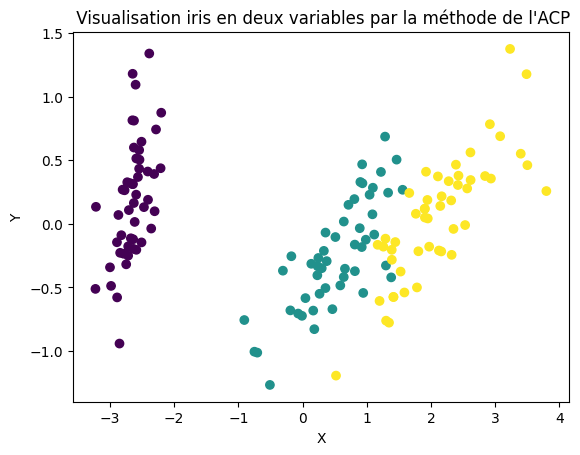

In [83]:
plt.scatter(IrisPCA[:,0], IrisPCA[:,1],c =iris1.target)
plt.title(" Visualisation iris en deux variables par la méthode de l'ACP")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

Et en LDA :

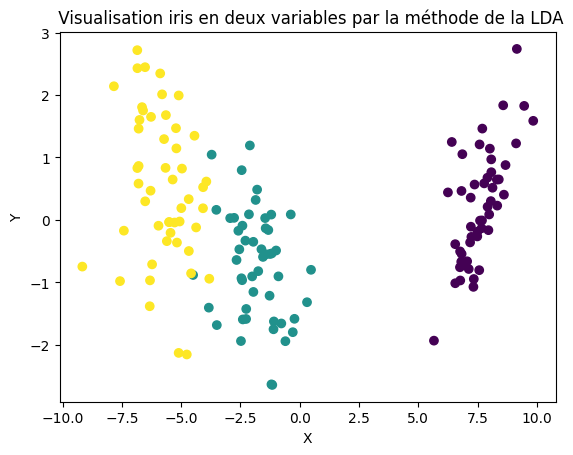

In [84]:
plt.scatter(IrisLDA[:,0], IrisLDA[:,1],c =iris1.target)
plt.title(" Visualisation iris en deux variables par la méthode de la LDA")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

3) On constate que en PCA les points sont mieux écartés les uns des autres ce qui donne une meilleure visualisation des individus grace à la maximisation de la variance alors qu'en LDA ce sont les groupes d'individus qui sont plus espacés entre eux pour une meilleure différentiation entre les groupes contrairement ou en pca les groupes se chevauchent un peu plus.